In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_excel(filename)

df.columns = df.columns.str.strip()

df = df[["Clean Text", "Final Label"]]

df = df.rename(columns={
    "Clean Text": "text",
    "Final Label": "label"
})

print("Kích thước dữ liệu:", df.shape)
print("Tên các cột:", df.columns.tolist())

display(df.head())


Saving final_labeled_clean_v3.xlsx to final_labeled_clean_v3.xlsx
Kích thước dữ liệu: (2087, 2)
Tên các cột: ['text', 'label']


,text,label
0,anh già rồi anh vẫn đỉnh rất,Positive
1,anh_trai đóng phản_diện chuẩn luôn_luôn,Positive
2,mình anh_em trong phim mà_lại,Neutral
3,anh ngoan bên thiên đường_máu làm trùm rồi qua...,Neutral
4,chén bà bầu bà bếp ngồi ôm gối thôi,Neutral


In [2]:
label_counts = df["label"].value_counts()
label_percent = df["label"].value_counts(normalize=True) * 100

label_distribution = pd.DataFrame({
    "Số lượng": label_counts,
    "Tỷ lệ (%)": label_percent.round(2)
})

print("Tổng số bình luận:", len(df))
display(label_distribution)

Tổng số bình luận: 2087


,Số lượng,Tỷ lệ (%)
label,,
Positive,1280,61.33
Neutral,438,20.99
Negative,369,17.68


In [4]:
from sklearn.model_selection import train_test_split

X=df["text"]
y=df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    stratify=y,
    random_state=18
)

print("Số mẫu Train:", len(X_train))
print("Số mẫu Test:", len(X_test))

Số mẫu Train: 1669
Số mẫu Test: 418


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score


cv = StratifiedKFold(
    n_splits=5, shuffle = True,
    random_state=18
)

model_bow = make_pipeline(
    CountVectorizer(ngram_range=(1,2)),
    LinearSVC(
        C=1.0, random_state=18
    )
)

scores_bow = cross_val_score(
    model_bow, X_train, y_train,
    cv = cv, scoring="f1_macro",
)

print("Macro F1 từng fold:", scores_bow)
print("Macro F1 trung bình:", scores_bow.mean())

Macro F1 từng fold: [0.60075704 0.50781846 0.59791226 0.55685379 0.53330374]
Macro F1 trung bình: 0.559329056794336


--Bow + LinearSVM--
              precision    recall  f1-score   support

    Negative     0.5250    0.3559    0.4242       295
     Neutral     0.4708    0.4829    0.4767       350
    Positive     0.7514    0.8145    0.7816      1024

    accuracy                         0.6639      1669
   macro avg     0.5824    0.5511    0.5609      1669
weighted avg     0.6525    0.6639    0.6545      1669



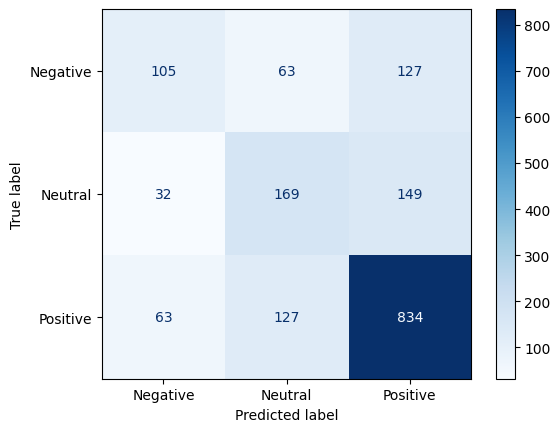

In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_bow = cross_val_predict(
    model_bow, X_train, y_train, cv=cv
)

print("--Bow + LinearSVM--")
print(classification_report(
    y_train, y_pred_bow, digits=4
))

labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    y_train, y_pred_bow, labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = labels
)

disp.plot(cmap="Blues", values_format="d")
plt.show()


**Thử với phương pháp OVO**

In [10]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_score

model_bow_ovo = make_pipeline(
    CountVectorizer(ngram_range=(1,2)),
    OneVsOneClassifier(
        LinearSVC(
            C=1.0, random_state=18
        )
    )
)

scores_ovo = cross_val_score(
    model_bow_ovo, X_train, y_train,
    cv=cv, scoring="f1_macro"
)

print("Macro F1 từng fold:", scores_ovo)
print("Macro F1 trung bình:", scores_ovo.mean())


Macro F1 từng fold: [0.6160028  0.49910699 0.60334228 0.56734848 0.54097023]
Macro F1 trung bình: 0.5653541556101821


**Điều chỉnh tham số cho BoW - OvR**

In [13]:
#Điều chỉnh tham số cho BoW-OVR
from sklearn.model_selection import GridSearchCV

param_grid_ovr= {
    "linearsvc__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10],
    "linearsvc__class_weight": [None, "balanced"]
}

grid_ovr = GridSearchCV(
    estimator = model_bow,
    param_grid = param_grid_ovr,
    cv = cv,
    scoring = "f1_macro",
    n_jobs = 2,
    return_train_score = True,
    refit=True
)

grid_ovr.fit(X_train, y_train)

print("Best Parameters:", grid_ovr.best_params_)
print("Best Macro F1:", grid_ovr.best_score_)


Best Parameters: {'linearsvc__C': 0.03, 'linearsvc__class_weight': 'balanced'}
Best Macro F1: 0.5858230861196534


In [14]:
from sklearn.model_selection import GridSearchCV

param_grid_bow = {
    "countvectorizer__ngram_range": [(1,1), (1,2), (1,3)],
    "countvectorizer__min_df": [1, 2, 3]
}
grid_bow = GridSearchCV(
    estimator = grid_ovr.best_estimator_,
    param_grid = param_grid_bow,
    cv=cv, scoring="f1_macro",
    n_jobs=2, refit=True
)

grid_bow.fit(X_train, y_train)

print("Best Parameters:", grid_bow.best_params_)
print("Best Macro F1:", grid_bow.best_score_)

Best Parameters: {'countvectorizer__min_df': 1, 'countvectorizer__ngram_range': (1, 2)}
Best Macro F1: 0.5858230861196534


-- BoW + SVM (OvR)--
              precision    recall  f1-score   support

    Negative     0.5362    0.3763    0.4422       295
     Neutral     0.5277    0.5171    0.5224       350
    Positive     0.7614    0.8320    0.7951      1024

    accuracy                         0.6854      1669
   macro avg     0.6084    0.5751    0.5866      1669
weighted avg     0.6726    0.6854    0.6756      1669



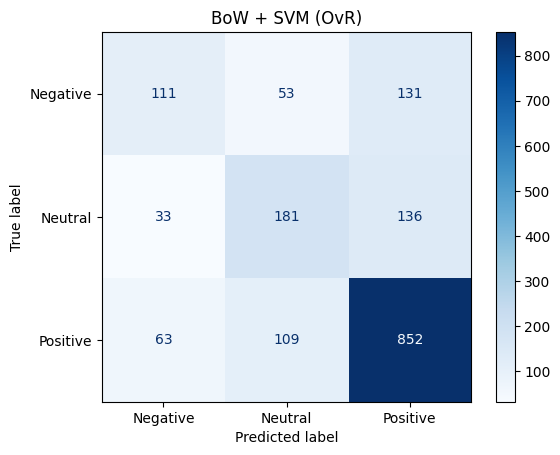

In [15]:
#đánh giá OvR sau tối ưu

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_ovr = grid_bow.best_estimator_

y_pred_ovr = cross_val_predict(
    best_ovr,
    X_train,
    y_train,
    cv=cv
)

print("-- BoW + SVM (OvR)--")
print(classification_report(
    y_train,
    y_pred_ovr,
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_ovr,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("BoW + SVM (OvR)")
plt.show()


**Điều chỉnh tham số cho Bow - SVM (OvO)**

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid_ovo = {
    "onevsoneclassifier__estimator__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10],
    "onevsoneclassifier__estimator__class_weight": [None, "balanced"]
}

grid_ovo = GridSearchCV(
    estimator=model_bow_ovo,
    param_grid = param_grid_ovo,
    cv=cv,
    scoring="f1_macro",
    n_jobs =2,
    refit=True
)

grid_ovo.fit(X_train, y_train)

print("Best Parameters:", grid_ovo.best_params_)
print("Best Macro F1:", grid_ovo.best_score_)

Best Parameters: {'onevsoneclassifier__estimator__C': 0.03, 'onevsoneclassifier__estimator__class_weight': 'balanced'}
Best Macro F1: 0.5862074410946864


In [17]:
from sklearn.model_selection import GridSearchCV

param_grid_ovo_2 = {
    "countvectorizer__ngram_range": [(1,1), (1,2), (1,3)],
    "countvectorizer__min_df": [1, 2, 3]
}

grid_ovo_2 = GridSearchCV(
    estimator=grid_ovo.best_estimator_,
    param_grid = param_grid_ovo_2,
    cv=cv,
    scoring="f1_macro",
    n_jobs =2,
    refit=True
)

grid_ovo_2.fit(X_train, y_train)

print("Best Parameters:", grid_ovo_2.best_params_)
print("Best Macro F1:", grid_ovo_2.best_score_)

Best Parameters: {'countvectorizer__min_df': 1, 'countvectorizer__ngram_range': (1, 2)}
Best Macro F1: 0.5862074410946864


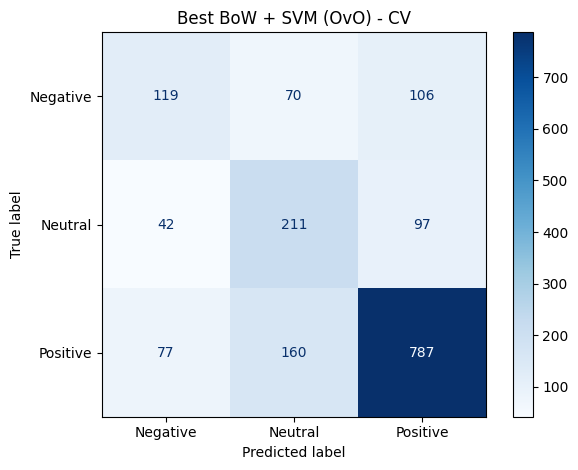

Best CV Macro F1: 0.5862074410946864
Đã lưu mô hình và kết quả đánh giá.


In [21]:

import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

best_bow = grid_ovo_2.best_estimator_

y_pred_best = cross_val_predict(
    best_bow, X_train, y_train, cv=cv
)

report = classification_report(
    y_train, y_pred_best,
    output_dict=True
)

metrics = pd.DataFrame(report).T
metrics.to_csv("best_bow_metrics.csv")

labels = ["Negative", "Neutral", "Positive"]

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_best,
    labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("Best BoW + SVM (OvO) - CV")
plt.tight_layout()
plt.savefig("best_bow_confusion_matrix.png", dpi=300)
plt.show()

joblib.dump(best_bow, "best_bow_svm.joblib")

print("Best CV Macro F1:", grid_ovo_2.best_score_)
print("Đã lưu mô hình và kết quả đánh giá.")
